# Nonlinear blocks

`Nonlinear(f)` applies a function of one sample, written in plain scalar
Python: `if`/`else`, `math`, `cmath`. The block loops over the chunk and
compiles the loop and `f` with numba. With `state=`, `f` also gets and
returns a state, so one block holds a whole tracking loop.

In [1]:
import cmath
import math

import matplotlib.pyplot as plt
import numpy as np

import sigline as sl

fs = 100e3

## 1. A function of one sample: an amplifier

The Rapp model of a solid-state amplifier: gain $G$ for small signals,
smooth saturation at $A_\mathrm{sat}$, phase unchanged,

$$|y| = \frac{G\,|x|}{\left(1 + (G|x|/A_\mathrm{sat})^{2p}\right)^{1/(2p)}}.$$

The input is a complex tone whose amplitude ramps from 0 to 3.

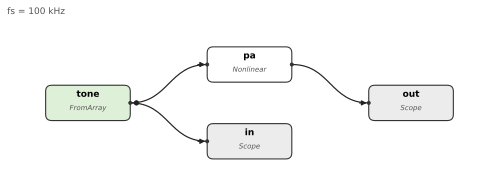

In [2]:
def rapp(x, gain=1.0, a_sat=1.0, p=2.0):
    r = abs(x)
    if r == 0.0:
        return 0j
    g = gain * r / (1 + (gain * r / a_sat) ** (2 * p)) ** (1 / (2 * p))
    return g * x / r


n = 20_000
amp = np.linspace(0, 3, n)
x = amp * np.exp(2j * np.pi * 1e3 * np.arange(n) / fs)

pa = sl.Nonlinear(rapp, params={"a_sat": 1.5}, name="pa")
rf_in, rf_out = sl.Scope("in"), sl.Scope("out")
src = sl.FromArray(x, name="tone")
src >> rf_in
src >> pa >> rf_out
d = sl.Diagram(rf_out, fs=fs)
d

compiled: numba, max |error| vs formula: 6.7e-16
max phase change: 2.1e-16 rad


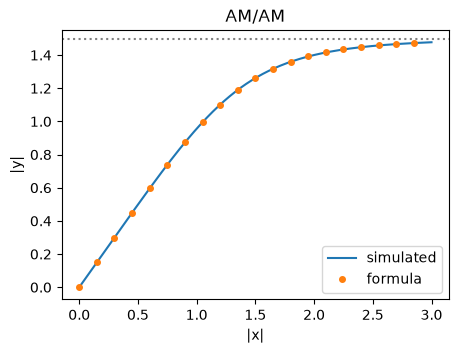

In [3]:
d.run(n=n)
r_in, r_out = np.abs(rf_in.data), np.abs(rf_out.data)
theory = r_in / (1 + (r_in / 1.5) ** 4) ** (1 / 4)
print(
    f"compiled: {pa.mode}, max |error| vs formula: {np.max(np.abs(r_out - theory)):.1e}"
)
dphi = np.angle(rf_out.data[1:] / rf_in.data[1:])
print(f"max phase change: {np.max(np.abs(dphi)):.1e} rad")

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.plot(r_in, r_out, label="simulated")
ax.plot(r_in[::1000], theory[::1000], "o", ms=4, label="formula")
ax.axhline(1.5, ls=":", c="gray")
ax.set(xlabel="|x|", ylabel="|y|", title="AM/AM")
ax.legend()
plt.show()

## 2. State: a Schmitt trigger

A comparator on a noisy sine chatters around each zero crossing. A Schmitt
trigger switches only when the input leaves the band from `lo` to `hi`, so
it needs to remember its output: that is its state. `f` returns
`(y, new_state)`.

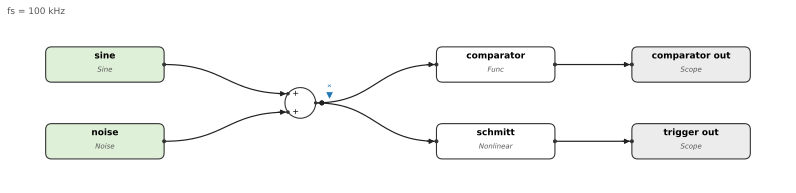

In [4]:
def schmitt(x, s, hi=0.3, lo=-0.3):
    if x > hi:
        s = 1.0
    elif x < lo:
        s = -1.0
    return s, s


noisy = sl.Sine(200.0, name="sine") + sl.Noise(0.1, seed=3, name="noise")
comp, trig = sl.Func(np.sign, name="comparator"), sl.Nonlinear(schmitt, state=-1.0)
y_comp, y_trig = sl.Scope("comparator out"), sl.Scope("trigger out")
noisy >> comp >> y_comp
noisy >> trig >> y_trig
d2 = sl.Diagram(y_comp, y_trig, fs=fs)
x_in = d2.probe(noisy, name="x")
d2

comparator out: 80 switches
trigger out: 8 switches
ideal: 8 (two per period of 200 Hz in 20 ms)


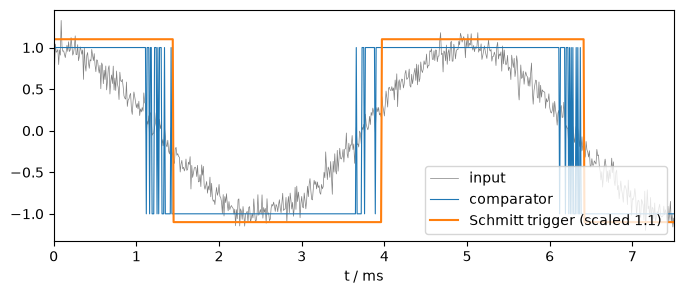

In [5]:
d2.run(0.02)
for sc in (y_comp, y_trig):
    print(f"{sc.name}: {np.count_nonzero(np.diff(sc.data))} switches")
print("ideal: 8 (two per period of 200 Hz in 20 ms)")

fig, ax = plt.subplots(figsize=(8, 3))
t = 1e3 * d2.t
ax.plot(t, x_in.data, lw=0.5, c="gray", label="input")
ax.plot(t, y_comp.data, lw=0.8, label="comparator")
ax.plot(t, 1.1 * y_trig.data, lw=1.5, label="Schmitt trigger (scaled 1.1)")
ax.set(xlabel="t / ms", xlim=(0, 7.5))
ax.legend(loc="lower right")
plt.show()

## 3. A tracking loop in one block: a PLL

A digital PLL for a complex tone: rotate the input by the estimated phase,
take the phase error $e$, update frequency and phase,

$$\hat\omega \leftarrow \hat\omega + \beta e, \qquad
\hat\varphi \leftarrow \hat\varphi + \hat\omega + \alpha e.$$

The state has two fields; `sl.state(phase=0, freq=0)` names them.
`dtype=` declares the output types, so the block need not call `f` to find
them. The input jumps from 500 Hz to 800 Hz at 50 ms.

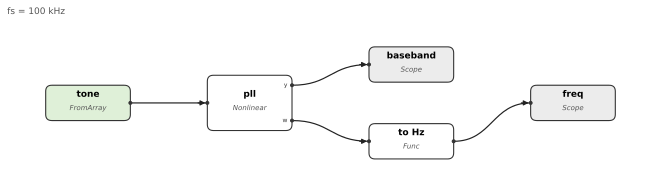

In [6]:
def pll(x, s, alpha=0.05, beta=0.002):
    y = x * cmath.exp(-1j * s.phase)
    e = math.atan2(y.imag, y.real)
    freq = s.freq + beta * e
    phase = (s.phase + freq + alpha * e) % (2 * math.pi)
    return (y, freq), type(s)(phase, freq)


n = int(0.1 * fs)
f_in = np.where(np.arange(n) < n // 2, 500.0, 800.0)
tone = sl.FromArray(np.exp(2j * np.pi * np.cumsum(f_in) / fs), name="tone")
loop = sl.Nonlinear(
    pll, state=sl.state(phase=0, freq=0), outputs=("y", "w"), dtype=(complex, float)
)
freq = sl.Scope("freq")
tone >> loop
loop["w"] >> sl.Func(lambda w: w * fs / (2 * np.pi), name="to Hz") >> freq
loop["y"] >> sl.Scope("baseband")
d3 = sl.Diagram(freq, fs=fs)
d3

at 40 ms:  500.00 Hz (input 500 Hz)
at 90 ms:  800.00 Hz (input 800 Hz)
state after the run: State(phase=0.05026548245745463, freq=0.050265482457436776)


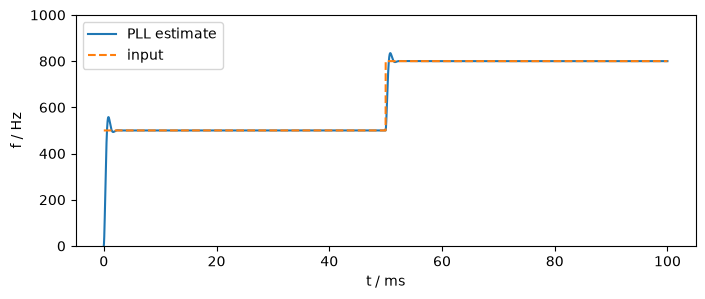

In [7]:
d3.run(n=n, chunk=4096)
for t0, f0 in ((0.04, 500.0), (0.09, 800.0)):
    k = int(t0 * fs)
    est = freq.data[k - 1000 : k].mean()
    print(f"at {1e3 * t0:.0f} ms: {est:7.2f} Hz (input {f0:.0f} Hz)")
print("state after the run:", loop.state)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(1e3 * d3.t, freq.data, label="PLL estimate")
ax.plot(1e3 * d3.t, f_in, "--", label="input")
ax.set(xlabel="t / ms", ylabel="f / Hz", ylim=(0, 1000))
ax.legend()
plt.show()

## 4. Inside a diagram loop: an AGC

An automatic gain control in blocks: a `Product` scales the input by the
gain, and a stateful `Nonlinear` integrates the level error into the next
gain, one sample later:

$$g[n+1] = g[n] + \mu\,(r - |y[n]|), \qquad y[n] = g[n]\,x[n].$$

The loop needs its output within each chunk, so it runs sample by sample as
a loop cluster. Every block in it has a numba kernel, so the whole loop is
compiled.

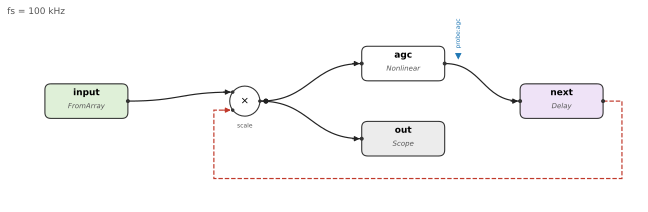

In [8]:
def agc(y, g, mu=0.002, ref=1.0):
    g = g + mu * (ref - abs(y))
    return g, g


n = 40_000
level = np.where(np.arange(n) < n // 2, 0.2, 3.0)
burst = sl.FromArray(level * np.exp(2j * np.pi * 2e3 * np.arange(n) / fs), name="input")
scale = sl.Product(name="scale")
update = sl.Nonlinear(agc, state=1.0, name="agc")
out = sl.Scope("out")
burst >> scale["x0"]
scale >> update >> sl.Delay(1, init=1.0, name="next") >> scale["x1"]
scale >> out
d4 = sl.Diagram(out, fs=fs)
gain = d4.probe(update)
d4

[<LoopCluster loop[scale, agc, next] numba>]
max |difference| to the python loop: 0.0e+00


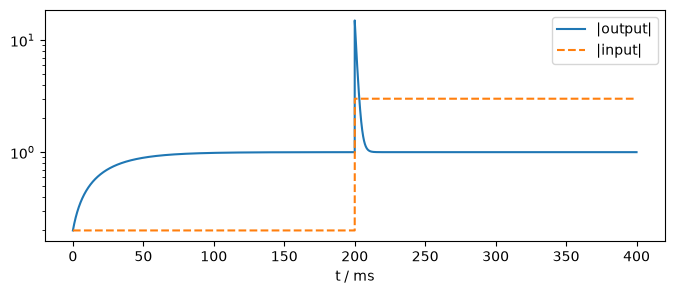

after the jump: peak 15.0, within 1 % after 12.0 ms


In [9]:
d4.run(n=n, chunk=4096)
print(d4.loops(4096))

# reference: the same recursion as a plain python loop
g, ref = 1.0, np.empty(n, complex)
xs = level * np.exp(2j * np.pi * 2e3 * np.arange(n) / fs)
for k in range(n):
    ref[k] = g * xs[k]
    g = g + 0.002 * (1.0 - abs(ref[k]))
print(f"max |difference| to the python loop: {np.max(np.abs(out.data - ref)):.1e}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.semilogy(1e3 * d4.t, np.abs(out.data), label="|output|")
ax.semilogy(1e3 * d4.t, level, "--", label="|input|")
ax.set(xlabel="t / ms")
ax.legend()
plt.show()
k = n // 2
settle = np.argmax(np.abs(np.abs(out.data[k:]) - 1) < 0.01) / fs
peak = np.abs(out.data[k:]).max()
print(f"after the jump: peak {peak:.1f}, within 1 % after {1e3 * settle:.1f} ms")

## Summary

- `Nonlinear(f)`: write one sample in scalar Python; numba compiles it.
- Arguments without defaults are inputs, with defaults parameters
  (`blk.params`). `state=` adds memory; `sl.state(...)` names it.
- Use `Func` for what NumPy vectorises, `Nonlinear` for scalar logic and
  memory.
- A `Nonlinear` inside a diagram loop compiles with the rest of the loop.